
# Student Performance Prediction
### Proyek Machine Learning — Regresi

Proyek ini bertujuan memprediksi nilai akhir siswa (`G3`) menggunakan fitur demografis, keluarga, sosial, dan kebiasaan belajar dari Student Performance Dataset.

## Objectives

- Memahami struktur dan karakteristik dataset.
- Melakukan exploratory data analysis (EDA).
- Menyiapkan preprocessing untuk fitur numerik dan kategorikal.
- Membandingkan baseline dengan tiga model regresi.
- Mengevaluasi model menggunakan MAE, RMSE, dan R².
- Menganalisis error prediksi dan mendokumentasikan keterbatasan model.

## Dataset

- **Sumber:** UCI Machine Learning Repository
- **Dataset:** Student Performance
- **Dataset ID:** 320
- **Target:** `G3`, yaitu nilai akhir siswa.

Referensi: https://doi.org/10.24432/C5TG7T

## Experiment Design

Kolom `G1` dan `G2` dikeluarkan dari fitur prediktor agar eksperimen berfokus pada prediksi nilai akhir tanpa menggunakan nilai periode sebelumnya.

Dataset dibagi menjadi 80% data latih dan 20% data uji dengan `random_state=42`.

Model dibandingkan menggunakan MAE, RMSE, dan R². Eksperimen ini menggunakan satu pembagian train/test dan belum mencakup hyperparameter tuning.

> Catatan: proyek ini merupakan eksperimen pembelajaran machine learning, bukan alat untuk menentukan kemampuan atau masa depan akademik siswa secara otomatis.


## 02. Data Loading & Initial Inspection

Dataset diambil dari UCI Machine Learning Repository melalui paket `ucimlrepo`.

In [1]:
%pip -q install ucimlrepo

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

student_performance = fetch_ucirepo(id=320)

X_source = student_performance.data.features.copy()
targets = student_performance.data.targets.copy()

df = pd.concat(
    [
        X_source.reset_index(drop=True),
        targets.reset_index(drop=True)
    ],
    axis=1
)

assert "G3" in df.columns

print("Ukuran fitur:", X_source.shape)
print("Ukuran target:", targets.shape)
print("Ukuran dataset:", df.shape)

display(df.head())


Ukuran fitur: (649, 30)
Ukuran target: (649, 3)
Ukuran dataset: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [3]:

print("Informasi dataset:")
df.info()

print("\nJumlah missing values:", int(df.isna().sum().sum()))
print("Jumlah baris duplikat:", int(df.duplicated().sum()))

print("\nStatistik deskriptif target G3:")
display(df["G3"].describe().to_frame("G3"))


Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 non-null    obj

,G3
count,649.000000
mean,11.906009
std,3.230656
min,0.000000
25%,10.000000
50%,12.000000
75%,14.000000
max,19.000000


## 03. Exploratory Data Analysis (EDA)

EDA dilakukan untuk memahami distribusi nilai akhir, tipe fitur, dan hubungan awal antara fitur numerik dengan target.

Korelasi menunjukkan asosiasi statistik dan tidak membuktikan hubungan sebab-akibat.

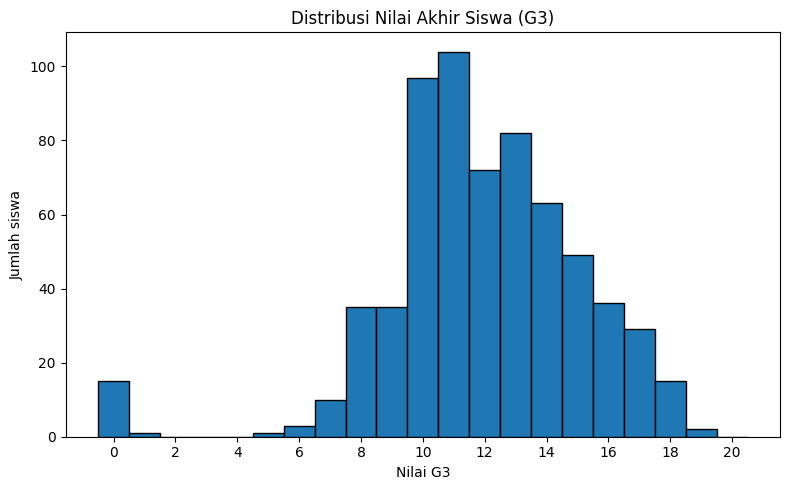

In [4]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["G3"],
    bins=np.arange(-0.5, 21.5, 1),
    edgecolor="black"
)

plt.title("Distribusi Nilai Akhir Siswa (G3)")
plt.xlabel("Nilai G3")
plt.ylabel("Jumlah siswa")
plt.xticks(range(0, 21, 2))
plt.tight_layout()
plt.show()

In [5]:

g3_counts = (
    df["G3"]
    .value_counts()
    .sort_index()
    .to_frame("Jumlah siswa")
)

display(g3_counts)


,Jumlah siswa
G3,
0,15
1,1
5,1
6,3
7,10
8,35
9,35
10,97
11,104


In [6]:

categorical_eda = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_eda = df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Jumlah fitur bertipe kategorikal:", len(categorical_eda))
print("Daftar fitur kategorikal:", categorical_eda)

print("\nJumlah kolom numerik, termasuk target:", len(numeric_eda))
print("Daftar kolom numerik:", numeric_eda)


Jumlah fitur bertipe kategorikal: 17
Daftar fitur kategorikal: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Jumlah kolom numerik, termasuk target: 16
Daftar kolom numerik: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


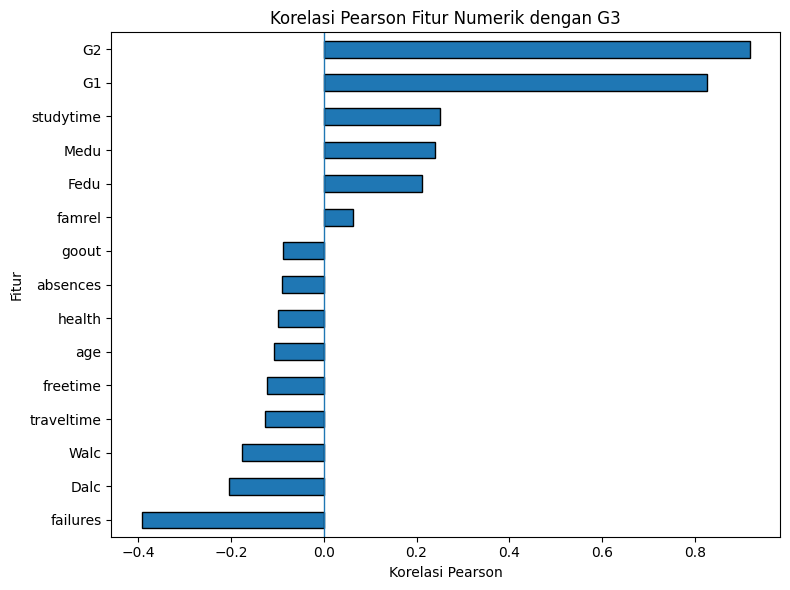

,Korelasi dengan G3
G2,0.919
G1,0.826
studytime,0.250
Medu,0.240
Fedu,0.212
famrel,0.063
goout,-0.088
absences,-0.091
health,-0.099
age,-0.107


In [7]:

numeric_corr = (
    df.select_dtypes(include=["number"])
    .corr()["G3"]
    .drop("G3")
    .sort_values()
)

plt.figure(figsize=(8, 6))

numeric_corr.plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Korelasi Pearson Fitur Numerik dengan G3")
plt.xlabel("Korelasi Pearson")
plt.ylabel("Fitur")
plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()

display(
    numeric_corr
    .to_frame("Korelasi dengan G3")
    .sort_values("Korelasi dengan G3", ascending=False)
    .round(3)
)


## 04. Feature Definition & Data Splitting

Target yang digunakan adalah `G3`, yaitu nilai akhir siswa.

Kolom `G1` dan `G2` dikeluarkan dari fitur prediktor untuk menyimulasikan skenario prediksi tanpa menggunakan nilai pada periode sebelumnya.

Dataset dibagi menjadi 80% data latih dan 20% data uji. Pembagian menggunakan `random_state=42` agar dapat direproduksi.


In [8]:

y = df["G3"].copy()

X = df.drop(
    columns=["G1", "G2", "G3"]
).copy()

categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)
print("Jumlah fitur kategorikal:", len(categorical_cols))
print("Jumlah fitur numerik:", len(numeric_cols))

print("\nFitur kategorikal:")
print(categorical_cols)

print("\nFitur numerik:")
print(numeric_cols)

assert X.shape == (649, 30)
assert y.shape == (649,)
assert len(categorical_cols) == 17
assert len(numeric_cols) == 13
assert not {"G1", "G2", "G3"}.intersection(X.columns)


Ukuran X: (649, 30)
Ukuran y: (649,)
Jumlah fitur kategorikal: 17
Jumlah fitur numerik: 13

Fitur kategorikal:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Fitur numerik:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [9]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

assert len(X_train) == 519
assert len(X_test) == 130


X_train: (519, 30)
X_test : (130, 30)
y_train: (519,)
y_test : (130,)



## 05. Preprocessing & Baseline

Fitur kategorikal diproses menggunakan One-Hot Encoding, sedangkan fitur numerik diteruskan tanpa transformasi tambahan.

Preprocessing ditempatkan di dalam `Pipeline` agar proses fitting transformasi dilakukan berdasarkan data latih.

Sebagai pembanding awal, digunakan `DummyRegressor` dengan strategi mean, yang memprediksi rata-rata target data latih untuk setiap observasi pada data uji.


In [10]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols
        ),
        (
            "numeric",
            "passthrough",
            numeric_cols
        )
    ]
)

baseline_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DummyRegressor(strategy="mean"))
    ]
)

baseline_pipeline.fit(X_train, y_train)

y_pred_baseline = baseline_pipeline.predict(X_test)

baseline_mae = mean_absolute_error(
    y_test, y_pred_baseline
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

baseline_r2 = r2_score(
    y_test, y_pred_baseline
)

print("=== BASELINE (MEAN) ===")
print(f"MAE  : {baseline_mae:.4f}")
print(f"RMSE : {baseline_rmse:.4f}")
print(f"R²   : {baseline_r2:.4f}")


=== BASELINE (MEAN) ===
MAE  : 2.3946
RMSE : 3.1726
R²   : -0.0322



## 06. Model Training

Tiga model regresi dibandingkan:

- **Linear Regression:** model regresi linear sebagai pembanding.
- **Random Forest Regressor:** menggabungkan banyak decision tree untuk menangkap pola nonlinier.
- **Gradient Boosting Regressor:** membangun model secara bertahap untuk memperbaiki kesalahan prediksi.

Semua model menggunakan data latih dan preprocessing yang sama. Parameter yang digunakan merupakan konfigurasi awal, bukan hasil hyperparameter tuning.


In [11]:

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

print("Model yang akan dilatih:")
for name in models:
    print("-", name)


Model yang akan dilatih:
- Linear Regression
- Random Forest
- Gradient Boosting


In [12]:

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"{name}: selesai dilatih.")

print("\nJumlah model yang berhasil dilatih:", len(trained_models))


Linear Regression: selesai dilatih.
Random Forest: selesai dilatih.
Gradient Boosting: selesai dilatih.

Jumlah model yang berhasil dilatih: 3



## 07. Model Evaluation & Comparison

Semua model dievaluasi menggunakan test set yang sama.

- **MAE:** rata-rata selisih absolut antara nilai aktual dan prediksi. Semakin rendah, semakin baik.
- **RMSE:** memberi penalti lebih besar terhadap kesalahan yang besar. Semakin rendah, semakin baik.
- **R²:** mengukur kemampuan model menjelaskan variasi target relatif terhadap prediksi menggunakan rata-rata target test set. Semakin tinggi, semakin baik.

Nilai R² dapat negatif jika model lebih buruk daripada prediksi konstan berdasarkan rata-rata target test set.


In [13]:

results = [
    {
        "Model": "Baseline (Mean)",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    }
]

predictions = {}

for name, pipeline in trained_models.items():
    pred = pipeline.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(
    results_df.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}"
    })
)


,Model,MAE,RMSE,R2
0,Random Forest,2.0264,2.8215,0.1837
1,Gradient Boosting,2.1049,2.8010,0.1955
2,Linear Regression,2.1564,2.8618,0.1602
3,Baseline (Mean),2.3946,3.1726,-0.0322


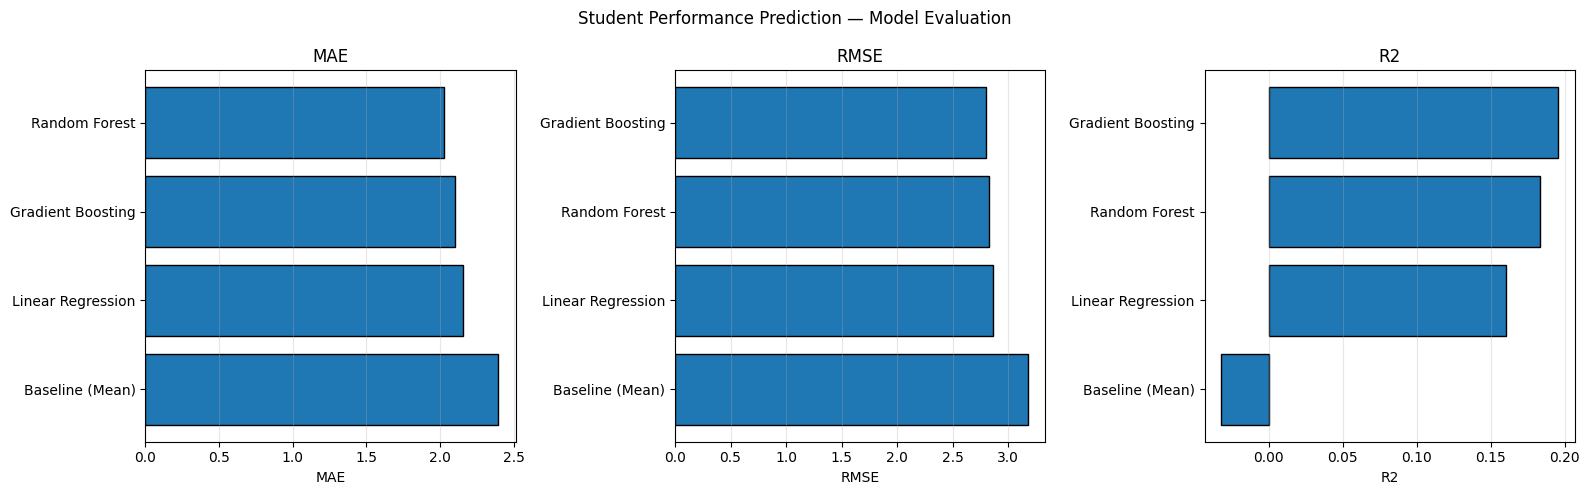

In [14]:
metrics = ["MAE", "RMSE", "R2"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, metrics):
    plot_data = results_df.sort_values(
        metric,
        ascending=(metric != "R2")
    )

    ax.barh(
        plot_data["Model"],
        plot_data[metric],
        edgecolor="black"
    )

    ax.set_title(metric)
    ax.set_xlabel(metric)
    ax.grid(axis="x", alpha=0.3)
    ax.invert_yaxis()

fig.suptitle(
    "Student Performance Prediction — Model Evaluation"
)

plt.tight_layout()
plt.show()

In [15]:

model_results = results_df[
    results_df["Model"].isin(trained_models.keys())
].copy()

best_mae_row = model_results.loc[
    model_results["MAE"].idxmin()
]

best_rmse_row = model_results.loc[
    model_results["RMSE"].idxmin()
]

best_r2_row = model_results.loc[
    model_results["R2"].idxmax()
]

print("=== MODEL TERBAIK BERDASARKAN METRIK ===")

print(
    f"MAE terendah  : {best_mae_row['Model']} "
    f"({best_mae_row['MAE']:.4f})"
)

print(
    f"RMSE terendah : {best_rmse_row['Model']} "
    f"({best_rmse_row['RMSE']:.4f})"
)

print(
    f"R² tertinggi  : {best_r2_row['Model']} "
    f"({best_r2_row['R2']:.4f})"
)


=== MODEL TERBAIK BERDASARKAN METRIK ===
MAE terendah  : Random Forest (2.0264)
RMSE terendah : Gradient Boosting (2.8010)
R² tertinggi  : Gradient Boosting (0.1955)



## 08. Prediction & Error Analysis

Analisis error digunakan untuk memahami perbedaan antara nilai aktual dan prediksi model pada test set.

Gradient Boosting dipilih untuk analisis lanjutan karena pada hasil eksperimen awal model ini memperoleh RMSE terendah dan R² tertinggi. Pemilihan ini berdasarkan hasil evaluasi, bukan asumsi sebelum pelatihan.

Error didefinisikan sebagai nilai aktual dikurangi nilai prediksi. Dengan definisi ini, error positif menunjukkan prediksi terlalu rendah (*underprediction*), sedangkan error negatif menunjukkan prediksi terlalu tinggi (*overprediction*).


In [16]:
analysis_model_name = best_rmse_row["Model"]

analysis_predictions = predictions[analysis_model_name]

comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": analysis_predictions
})

comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
)

comparison["Absolute_Error"] = (
    comparison["Error"].abs()
)

print("Model untuk analisis error:", analysis_model_name)

display(comparison.head(10).round(3))

Model untuk analisis error: Gradient Boosting


,Actual,Predicted,Error,Absolute_Error
0,19,13.201,5.799,5.799
1,12,12.535,-0.535,0.535
2,18,14.454,3.546,3.546
3,11,12.934,-1.934,1.934
4,11,11.513,-0.513,0.513
5,17,13.616,3.384,3.384
6,18,13.896,4.104,4.104
7,8,8.946,-0.946,0.946
8,10,12.512,-2.512,2.512
9,11,12.427,-1.427,1.427


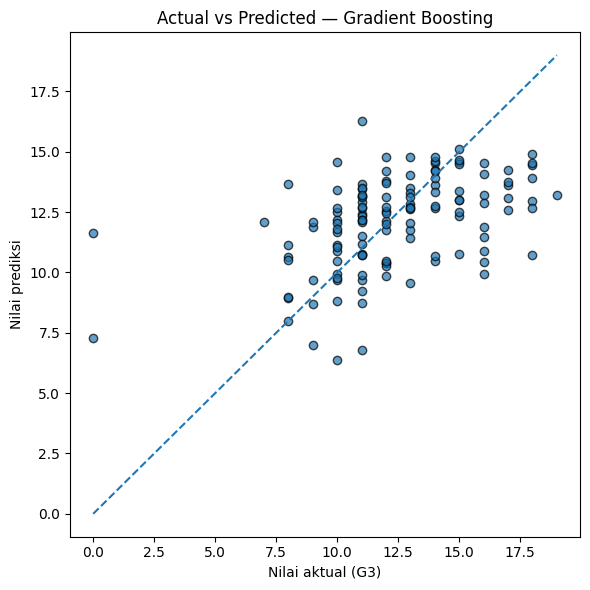

In [17]:

plt.figure(figsize=(6, 6))

plt.scatter(
    comparison["Actual"],
    comparison["Predicted"],
    alpha=0.7,
    edgecolors="black"
)

min_value = min(
    comparison["Actual"].min(),
    comparison["Predicted"].min()
)

max_value = max(
    comparison["Actual"].max(),
    comparison["Predicted"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted — {analysis_model_name}")
plt.xlabel("Nilai aktual (G3)")
plt.ylabel("Nilai prediksi")
plt.tight_layout()
plt.show()


In [18]:

print("Rata-rata error:", round(comparison["Error"].mean(), 3))
print("Median error:", round(comparison["Error"].median(), 3))

print("\nRingkasan absolute error:")
display(
    comparison["Absolute_Error"]
    .describe()
    .round(3)
    .to_frame("Absolute_Error")
)


Rata-rata error: 0.254
Median error: 0.125

Ringkasan absolute error:


,Absolute_Error
count,130.000
mean,2.105
std,1.855
min,0.008
25%,0.637
50%,1.714
75%,3.035
max,11.616


In [19]:

largest_errors = (
    comparison
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

display(largest_errors.round(3))


,Actual,Predicted,Error,Absolute_Error
121,0,11.616,-11.616,11.616
68,0,7.286,-7.286,7.286
34,18,10.728,7.272,7.272
118,16,9.919,6.081,6.081
0,19,13.201,5.799,5.799
42,8,13.656,-5.656,5.656
24,16,10.422,5.578,5.578
46,18,12.658,5.342,5.342
43,11,16.274,-5.274,5.274
30,16,10.908,5.092,5.092


In [20]:
comparison["Error_Category"] = pd.cut(
    comparison["Absolute_Error"],
    bins=[-np.inf, 1, 2, np.inf],
    labels=[
        "Error <= 1",
        "1 < Error <= 2",
        "Error > 2"
    ]
)

error_summary = (
    comparison["Error_Category"]
    .value_counts(sort=False)
    .to_frame("Jumlah")
)

error_summary["Persentase (%)"] = (
    error_summary["Jumlah"] / len(comparison) * 100
)

display(error_summary.round(2))

,Jumlah,Persentase (%)
Error_Category,,
Error <= 1,41,31.54
1 < Error <= 2,34,26.15
Error > 2,55,42.31



## 09. Final Validation

Pemeriksaan akhir memastikan bahwa ukuran dataset, pembagian train/test, pemilihan fitur, model yang dilatih, dan hasil evaluasi konsisten dengan rancangan eksperimen.

Pemeriksaan ini merupakan validasi struktur dan hasil komputasi, bukan jaminan bahwa model akan berkinerja sama pada data baru.


In [21]:

# Ukuran dataset dan target
assert X.shape == (649, 30)
assert y.shape == (649,)

# Ukuran train/test
assert X_train.shape == (519, 30)
assert X_test.shape == (130, 30)
assert y_train.shape == (519,)
assert y_test.shape == (130,)

# Tidak ada target atau nilai periode sebelumnya di fitur
assert not {"G1", "G2", "G3"}.intersection(X.columns)

# Jumlah dan nama model
assert set(trained_models.keys()) == {
    "Linear Regression",
    "Random Forest",
    "Gradient Boosting"
}

# Hasil mencakup baseline dan tiga model utama
assert len(results_df) == 4
assert "Baseline (Mean)" in results_df["Model"].values

# Pastikan metrik tidak kosong dan nilainya finite
metric_columns = ["MAE", "RMSE", "R2"]

assert results_df[metric_columns].notna().all().all()

assert np.isfinite(
    results_df[metric_columns].to_numpy()
).all()

# Semua prediksi dan hasil analisis memiliki jumlah baris yang tepat
assert all(len(pred) == len(y_test) for pred in predictions.values())
assert len(comparison) == len(y_test)

print("Semua pemeriksaan dasar berhasil.")

display(
    results_df[["Model", "MAE", "RMSE", "R2"]].round(4)
)


Semua pemeriksaan dasar berhasil.


,Model,MAE,RMSE,R2
0,Random Forest,2.0264,2.8215,0.1837
1,Gradient Boosting,2.1049,2.8010,0.1955
2,Linear Regression,2.1564,2.8618,0.1602
3,Baseline (Mean),2.3946,3.1726,-0.0322



## 10. Final Conclusion & Limitations

### Kesimpulan

Eksperimen ini membandingkan tiga model regresi untuk memprediksi nilai akhir siswa (`G3`) berdasarkan 30 fitur non-nilai, tanpa menggunakan `G1` dan `G2` sebagai fitur prediktor.

Pada test set yang terdiri dari 130 observasi, hasil evaluasi menunjukkan:

- **Random Forest** memperoleh MAE terendah sebesar 2.0264.
- **Gradient Boosting** memperoleh RMSE terendah sebesar 2.8010 dan R² tertinggi sebesar 0.1955.
- Ketiga model utama mengungguli baseline berdasarkan MAE, RMSE, dan R² pada pembagian data yang diuji.

Hasil tersebut menunjukkan bahwa model utama memberikan prediksi yang lebih baik daripada baseline sederhana dalam eksperimen ini. Namun, R² yang relatif rendah menunjukkan bahwa sebagian besar variasi nilai akhir belum dapat dijelaskan oleh model.

### Keterbatasan

- Evaluasi menggunakan satu pembagian train/test dengan `random_state=42`.
- Parameter model belum melalui hyperparameter tuning.
- Performa dapat berubah pada pembagian data atau populasi siswa yang berbeda.
- Error prediksi bervariasi antarobservasi sehingga prediksi individual perlu ditafsirkan dengan hati-hati.
- Hubungan statistik dan hasil prediksi tidak membuktikan sebab-akibat.

### Pengembangan Berikutnya

Pengembangan lanjutan dapat mencakup cross-validation, hyperparameter tuning, dan analisis error yang lebih mendalam.

Test set sebaiknya tetap dipertahankan untuk evaluasi akhir dan tidak digunakan berulang kali untuk memilih konfigurasi model.

Proyek ini merupakan eksperimen pembelajaran machine learning. Prediksi tidak boleh digunakan sebagai satu-satunya dasar untuk menilai kemampuan, potensi, atau masa depan akademik siswa.
